In [1]:
from google.colab import drive
import cv2, glob, os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

Mounted at /content/drive
Dimensions: 612 x 408 px, 3 channels
Gray: t=116, foreground=29.6%, components=2483
Lab b*: t=156, foreground=21.7%, components=117


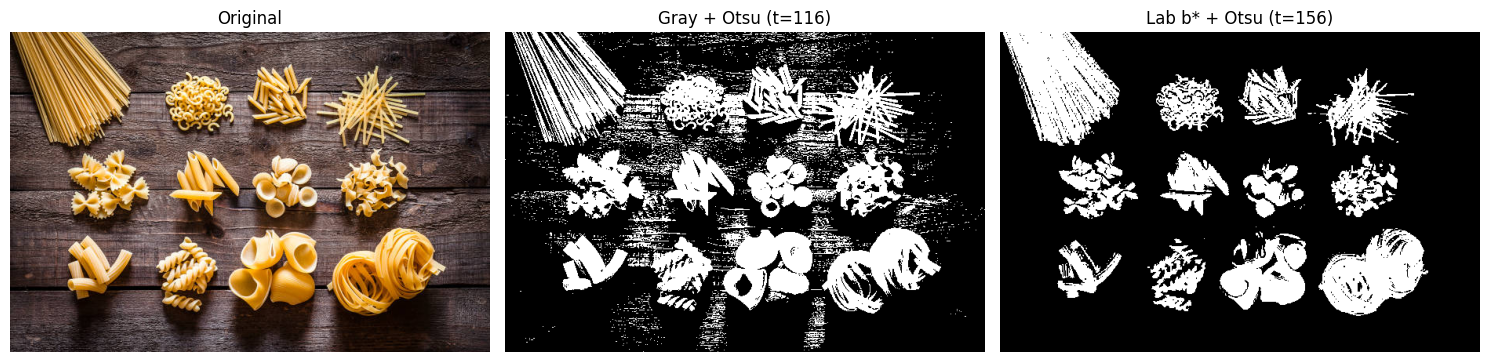

True

In [2]:
drive.mount('/content/drive')

image = '/content/drive/MyDrive/CV/CV_Act_8/Photos/original_pasta.jpg'
img = cv2.imread(image)
assert img is not None, "Check the image path"

print(f"Dimensions: {img.shape[1]} x {img.shape[0]} px, {img.shape[2]} channels")


#Thresholding using grayscale + Otsu
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
t_gray, bin_gray = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

#Thresholding through Lab b* (yellowness) + Otsu
b = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)[:, :, 2]
t_lab, bin_lab = cv2.threshold(b, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

for name, t, bw in [("Gray", t_gray, bin_gray), ("Lab b*", t_lab, bin_lab)]:
    n = cv2.connectedComponents(bw)[0] - 1
    print(f"{name}: t={t:.0f}, foreground={np.mean(bw == 255)*100:.1f}%, components={n}")

panels = [("Original", cv2.cvtColor(img, cv2.COLOR_BGR2RGB)),
          (f"Gray + Otsu (t={t_gray:.0f})", bin_gray),
          (f"Lab b* + Otsu (t={t_lab:.0f})", bin_lab)]
plt.figure(figsize=(15, 4))
for i, (title, im) in enumerate(panels, 1):
    plt.subplot(1, 3, i)
    plt.imshow(im, cmap="gray")
    plt.title(title)
    plt.axis("off")
plt.tight_layout()
plt.show()

binary = bin_lab
cv2.imwrite("binary_image.png", binary)

Original               foreground= 21.7%  objects=117
Erosion Rect 3x3       foreground= 13.9%  objects=231
Dilation Rect 3x3      foreground= 27.8%  objects=29
Erosion Rect 5x5       foreground=  8.8%  objects=177
Dilation Rect 5x5      foreground= 31.1%  objects=19
Erosion Ellipse 5x5    foreground= 10.4%  objects=232
Dilation Ellipse 5x5   foreground= 30.0%  objects=20


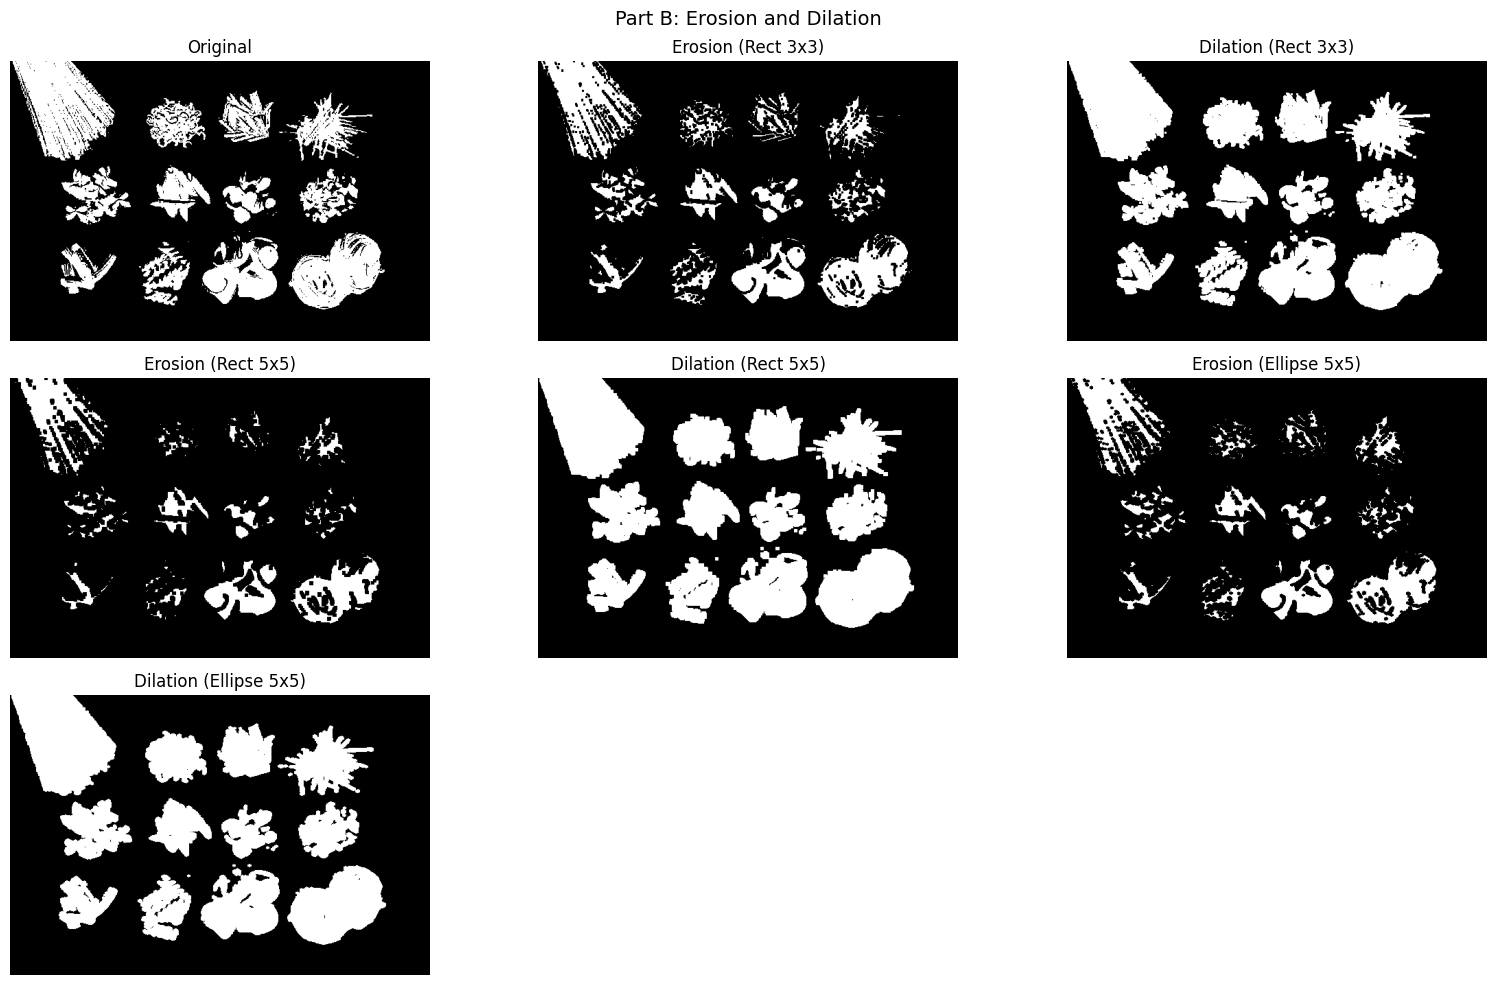

In [3]:
#saves the images to the output drive, saves me the pain
out_dir = '/content/drive/MyDrive/CV/CV_Act_8/Photos/'

#helper function to calcylate some stats (foreground % (how much of image is white), object (number of separte blobs))
def stats(im):
    fg = np.mean(im == 255) * 100
    n = cv2.connectedComponents(im)[0] - 1
    return fg, n

kernels = {
    "Rect 3x3":    cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3)),
    "Rect 5x5":    cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5)),
    "Ellipse 5x5": cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5)),
}

fg, n = stats(binary)
print(f"{'Original':22s} foreground={fg:5.1f}%  objects={n}")

results = [("Original", binary)]
for name, k in kernels.items():
    for op, func in [("Erosion", cv2.erode), ("Dilation", cv2.dilate)]:
        out = func(binary, k, iterations=1)
        fg, n = stats(out)
        print(f"{op + ' ' + name:22s} foreground={fg:5.1f}%  objects={n}")
        results.append((f"{op} ({name})", out))
        cv2.imwrite(out_dir + f"{op.lower()}_{name.replace(' ', '_').lower()}.png", out)

plt.figure(figsize=(16, 10))
for i, (title, im) in enumerate(results, 1):
    plt.subplot(3, 3, i)
    plt.imshow(im, cmap="gray")
    plt.title(title)
    plt.axis("off")
plt.suptitle("Part B: Erosion and Dilation", fontsize=14)
plt.tight_layout()
plt.savefig(out_dir + "part_b_panel.png", dpi=150, bbox_inches="tight")
plt.show()


In [4]:
#helper function
def count_holes(im):
    #black regions not touching the border = holes inside white objects
    inv = cv2.bitwise_not(im)
    n, _, st, _ = cv2.connectedComponentsWithStats(inv)
    h, w = im.shape
    return sum(1 for i in range(1, n)
               if st[i, 0] > 0 and st[i, 1] > 0
               and st[i, 0] + st[i, 2] < w and st[i, 1] + st[i, 3] < h)

Original               foreground= 21.7%  objects= 117  holes=522
Opening Rect 3x3       foreground= 20.0%  objects=  92  holes=262
Closing Rect 3x3       foreground= 24.0%  objects=  47  holes=65
Opening Rect 5x5       foreground= 16.5%  objects=  78  holes=88
Closing Rect 5x5       foreground= 25.4%  objects=  25  holes=25
Opening Ellipse 5x5    foreground= 17.9%  objects=  90  holes=168
Closing Ellipse 5x5    foreground= 25.0%  objects=  35  holes=29


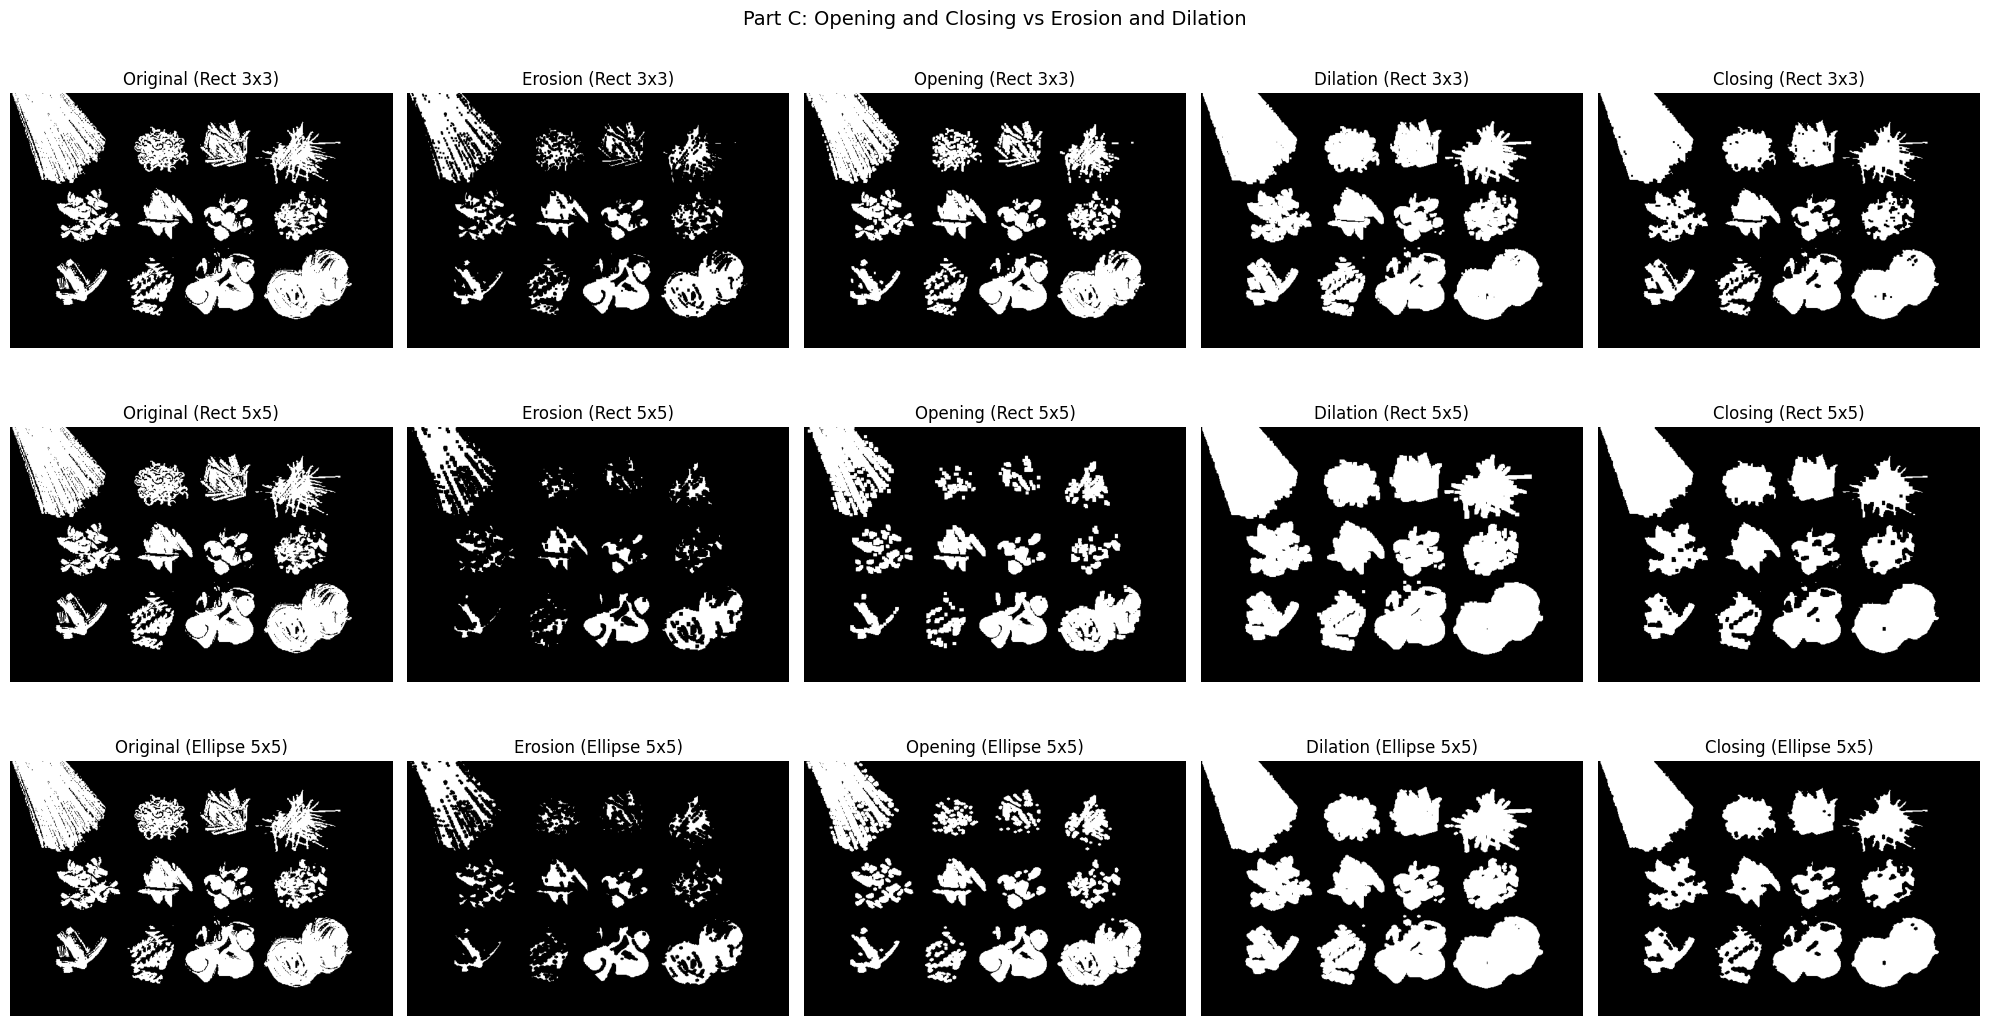

In [5]:
fg, n = stats(binary)
print(f"{'Original':22s} foreground={fg:5.1f}%  objects={n:4d}  holes={count_holes(binary)}")

ops = {
    "Erosion":  lambda k: cv2.erode(binary, k),
    "Opening":  lambda k: cv2.morphologyEx(binary, cv2.MORPH_OPEN, k),
    "Dilation": lambda k: cv2.dilate(binary, k),
    "Closing":  lambda k: cv2.morphologyEx(binary, cv2.MORPH_CLOSE, k),
}

plt.figure(figsize=(20, 11))
i = 1
for name, k in kernels.items():
    plt.subplot(3, 5, i)
    plt.imshow(binary, cmap="gray")
    plt.title(f"Original ({name})")
    plt.axis("off")
    i += 1
    for op, func in ops.items():
        out = func(k)
        fg, n = stats(out)
        if op in ("Opening", "Closing"):
            print(f"{op + ' ' + name:22s} foreground={fg:5.1f}%  objects={n:4d}  holes={count_holes(out)}")
            cv2.imwrite(out_dir + f"{op.lower()}_{name.replace(' ', '_').lower()}.png", out)
        plt.subplot(3, 5, i); plt.imshow(out, cmap="gray")
        plt.title(f"{op} ({name})"); plt.axis("off")
        i += 1

plt.suptitle("Part C: Opening and Closing vs Erosion and Dilation", fontsize=14)
plt.tight_layout()
plt.savefig(out_dir + "part_c_panel.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
amount = 0.05 #5% of pixels are corrupted: half set to white, half to black
rng = np.random.default_rng(42)
r = rng.random(binary.shape)
noisy = binary.copy()
noisy[r < amount / 2] = 0 # pepper
noisy[r > 1 - amount / 2] = 255 # salt
cv2.imwrite(out_dir + "noisy_image.png", noisy)

True

In [11]:
def iou(a, b):
  #measures intersection over union (how much of the white pixels overlap with the clean image)
    a, b = a == 255, b == 255
    return (a & b).sum() / (a | b).sum()

def report(name, im):
    fg_pct, n = stats(im)
    print(f"{name:24s} foreground={fg_pct:5.1f}%  objects={n:5d}  "
          f"holes={count_holes(im):5d}  IoU vs clean={iou(im, binary):.3f}")

Clean                    foreground= 21.7%  objects=  117  holes=  522  IoU vs clean=1.000
Noisy                    foreground= 23.1%  objects= 4171  holes= 1262  IoU vs clean=0.895
Opening (Rect 3x3)       foreground= 18.8%  objects=  142  holes=  572  IoU vs clean=0.866
Closing (Rect 3x3)       foreground= 26.7%  objects= 3390  holes=   72  IoU vs clean=0.810
Open -> Close (Rect 3x3) foreground= 20.5%  objects=   49  holes=   56  IoU vs clean=0.861
Opening (Rect 5x5)       foreground= 13.6%  objects=  114  holes=  176  IoU vs clean=0.626
Closing (Rect 5x5)       foreground= 30.8%  objects= 2224  holes=   34  IoU vs clean=0.702
Open -> Close (Rect 5x5) foreground= 15.1%  objects=   46  holes=   15  IoU vs clean=0.656


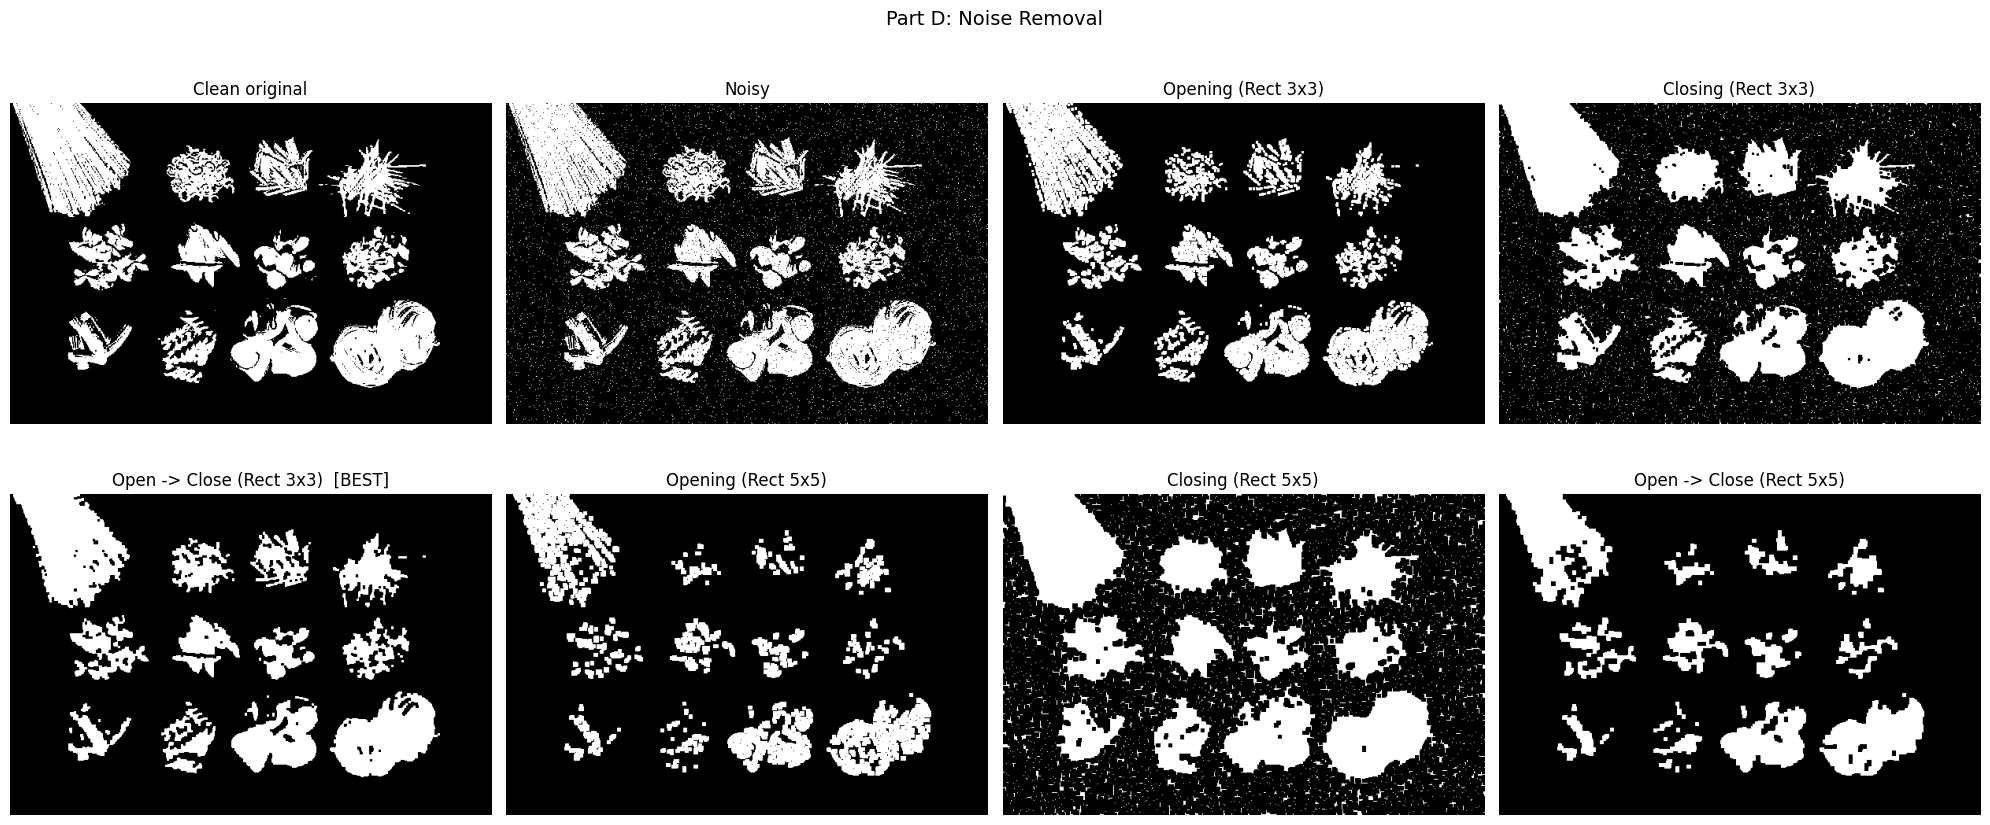

In [13]:
report("Clean", binary)
report("Noisy", noisy)

panels = [("Clean original", binary), ("Noisy", noisy)]
results_d = {}
for size in (3, 5):
    k = cv2.getStructuringElement(cv2.MORPH_RECT, (size, size))
    opened = cv2.morphologyEx(noisy, cv2.MORPH_OPEN, k)
    closed = cv2.morphologyEx(noisy, cv2.MORPH_CLOSE, k)
    open_close = cv2.morphologyEx(opened, cv2.MORPH_CLOSE, k)
    for name, im in [(f"Opening (Rect {size}x{size})", opened),
                     (f"Closing (Rect {size}x{size})", closed),
                     (f"Open -> Close (Rect {size}x{size})", open_close)]:
        report(name, im)
        results_d[name] = im
        panels.append((name, im))

#save the best result and the comparison panel
best_name = "Open -> Close (Rect 3x3)"
cv2.imwrite(out_dir + "best_noise_removal.png", results_d[best_name])

plt.figure(figsize=(20, 9))
for i, (title, im) in enumerate(panels, 1):
    plt.subplot(2, 4, i)
    plt.imshow(im, cmap="gray")
    plt.title(title + ("  [BEST]" if title == best_name else ""))
    plt.axis("off")
plt.suptitle("Part D: Noise Removal", fontsize=14)
plt.tight_layout()
plt.savefig(out_dir + "part_d_panel.png", dpi=150, bbox_inches="tight")
plt.show()

In [14]:
#crop out the bottom right region (shells and tagliatelle) since it has the most interesting little holes
crop = binary[225:408, 270:612]

In [15]:
def count_large(im, min_area=300):
    #objects big enough to count as a pasta group, ignoring small fragments
    n, _, st, _ = cv2.connectedComponentsWithStats(im)
    return int((st[1:, cv2.CC_STAT_AREA] >= min_area).sum())


Original       holes= 98  pasta groups=2
Closing  3x3   holes= 17  pasta groups=2
Closing  5x5   holes=  6  pasta groups=2
Closing  7x7   holes=  3  pasta groups=2
Closing 15x15  holes=  0  pasta groups=2
Closing 19x19  holes=  0  pasta groups=2
Closing 25x25  holes=  0  pasta groups=1   <-- groups merged


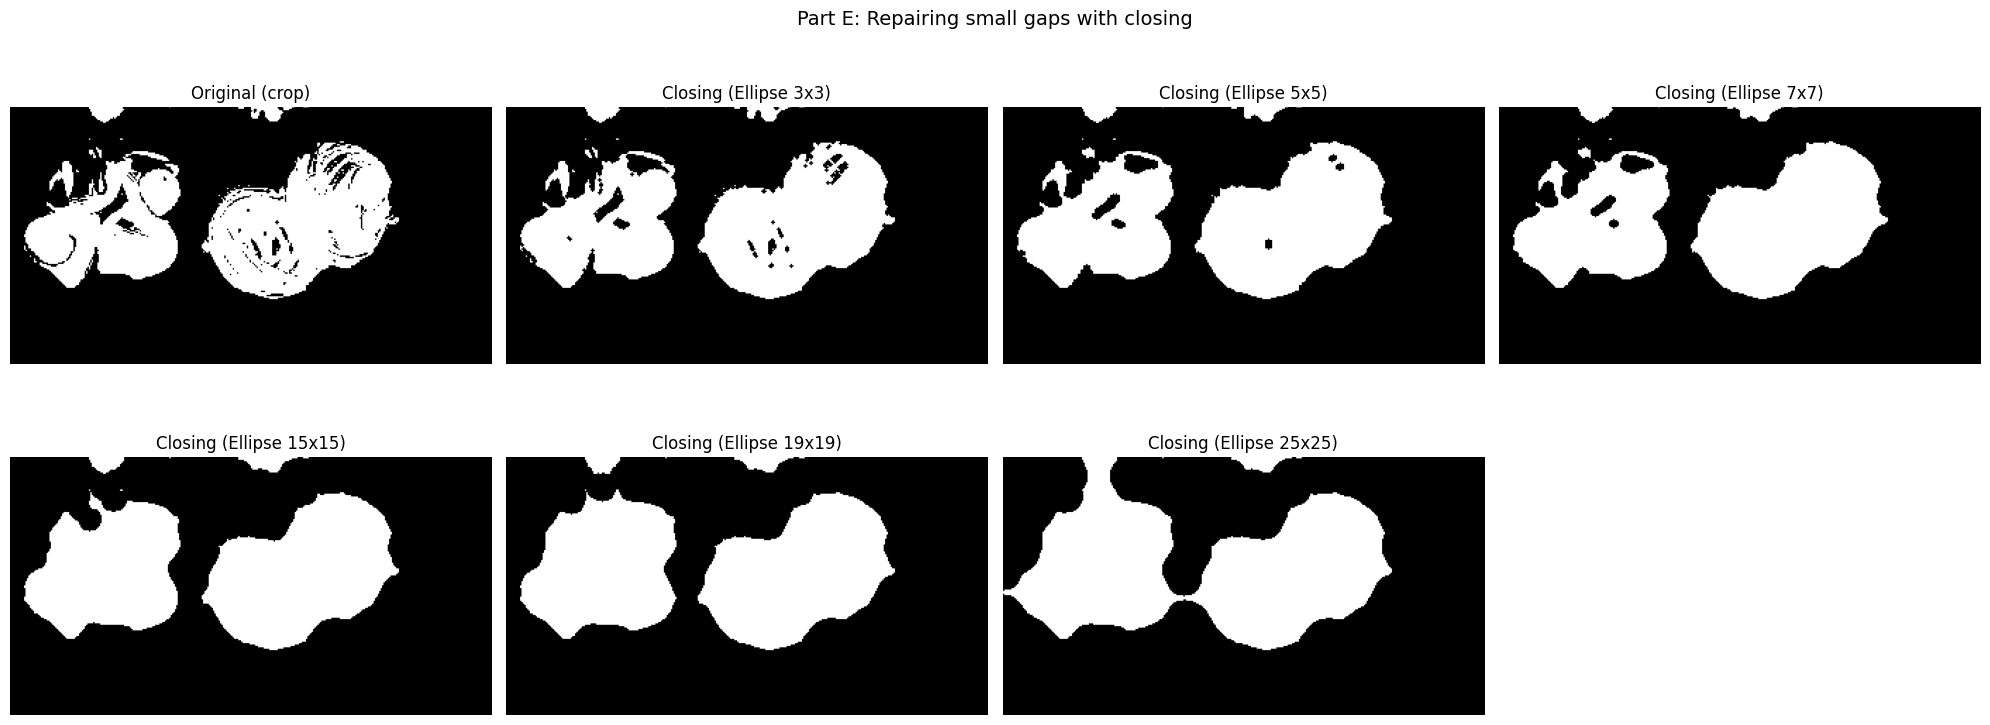

True

In [16]:
print(f"{'Original':14s} holes={count_holes(crop):3d}  pasta groups={count_large(crop)}")

panels = [("Original (crop)", crop)]
for size in (3, 5, 7, 15, 19, 25):
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (size, size))
    closed = cv2.morphologyEx(crop, cv2.MORPH_CLOSE, k)
    groups = count_large(closed)
    print(f"Closing {size:2d}x{size:<2d}  holes={count_holes(closed):3d}  pasta groups={groups}"
          + ("   <-- groups merged" if groups < 2 else ""))
    panels.append((f"Closing (Ellipse {size}x{size})", closed))

plt.figure(figsize=(20, 8))
for i, (title, im) in enumerate(panels, 1):
    plt.subplot(2, 4, i)
    plt.imshow(im, cmap="gray")
    plt.title(title)
    plt.axis("off")
plt.suptitle("Part E: Repairing small gaps with closing", fontsize=14)
plt.tight_layout()
plt.savefig(out_dir + "part_e_panel.png", dpi=150, bbox_inches="tight")
plt.show()

cv2.imwrite(out_dir + "part_e_before.png", crop)
cv2.imwrite(out_dir + "part_e_after.png",
            cv2.morphologyEx(crop, cv2.MORPH_CLOSE,
                             cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))))